In [1]:
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.impute import KNNImputer
from sklearn.preprocessing import LabelEncoder
import matplotlib as mpl
import seaborn as sns

# 한글 폰트 설정 (전역)
mpl.rcParams['font.family'] = 'NanumGothic'

# 마이너스 폰트 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

train_data = pd.read_csv("./data/train.csv")
test_data = pd.read_csv("./data/test.csv")

In [2]:
train_data

,ID,매물확인방식,보증금,월세,전용면적,해당층,총층,방향,방수,욕실수,주차가능여부,총주차대수,관리비,중개사무소,제공플랫폼,게재일,허위매물여부
0,TRAIN_0000,현장확인,402500000.0,470000,NaN,NaN,15.0,서향,1.0,1.0,가능,40.0,96,t93Nt6I2I0,B플랫폼,2024-10-09,0
1,TRAIN_0001,현장확인,170500000.0,200000,NaN,3.0,4.0,남동향,2.0,1.0,불가능,NaN,0,q39iV5J4E6,D플랫폼,2024-12-26,0
2,TRAIN_0002,전화확인,114000000.0,380000,NaN,2.0,3.0,동향,1.0,1.0,불가능,NaN,0,b03oE4G3F6,A플랫폼,2024-11-28,0
3,TRAIN_0003,현장확인,163500000.0,30000,36.30,3.0,9.0,남동향,2.0,1.0,가능,13.0,10,G52Iz8V2B9,A플랫폼,2024-11-26,0
4,TRAIN_0004,현장확인,346000000.0,530000,NaN,3.0,3.0,동향,2.0,1.0,불가능,NaN,0,N45gM0M7R0,B플랫폼,2024-06-25,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2447,TRAIN_2447,서류확인,159000000.0,550000,48.95,3.0,3.0,남향,2.0,1.0,불가능,NaN,0,d22DX4Y4P8,B플랫폼,2024-11-16,0
2448,TRAIN_2448,서류확인,158500000.0,750000,NaN,2.0,4.0,남향,1.0,1.0,불가능,NaN,2,g99sy3I3R8,A플랫폼,2024-10-06,0
2449,TRAIN_2449,전화확인,329000000.0,610000,17.50,8.0,20.0,남서향,1.0,1.0,가능,29.0,10,G52Iz8V2B9,B플랫폼,2024-05-15,0
2450,TRAIN_2450,현장확인,31000000.0,400000,22.87,8.0,9.0,남동향,2.0,1.0,가능,NaN,8,m69GM9O9B3,B플랫폼,2024-08-06,0


In [3]:
# from sklearn.experimental import enable_iterative_imputer
# from sklearn.impute import IterativeImputer
# from sklearn.linear_model import BayesianRidge
# import pandas as pd

# # 숫자형 컬럼만 선택
# numeric_cols = train_data.select_dtypes(include=["number"])

# # IterativeImputer 설정 (Bayesian Ridge 회귀 사용)
# imputer = IterativeImputer(estimator=BayesianRidge(), random_state=42)

# # 결측치 채우기
# train_data_imputed = pd.DataFrame(imputer.fit_transform(numeric_cols), columns=numeric_cols.columns)
# test_data_imputed = pd.DataFrame(imputer.transform(numeric_cols), columns=numeric_cols.columns)

# # 기존 데이터프레임 업데이트
# train_data.update(train_data_imputed)
# test_data.update(test_data_imputed)


from sklearn.impute import KNNImputer

# ✅ 숫자형 컬럼만 선택 (범주형 컬럼 제거)
numeric_cols_train = train_data.select_dtypes(include=["number"]).columns.drop("허위매물여부")
numeric_cols_test = test_data.select_dtypes(include=["number"]).columns

# ✅ KNN Imputer 설정 (k=5)
imputer = KNNImputer(n_neighbors=5)

# ✅ train 데이터 결측치 채우기
train_data[numeric_cols_train] = imputer.fit_transform(train_data[numeric_cols_train])

# ✅ test 데이터도 train에서 학습한 imputer를 적용
test_data[numeric_cols_test] = imputer.transform(test_data[numeric_cols_test])  # `fit_transform()` ❌

# ✅ 확인
print("🚀 KNN Imputer 적용 완료!")
print(f"train_data 결측치 개수:\n{train_data.isnull().sum().sum()}")
print(f"test_data 결측치 개수:\n{test_data.isnull().sum().sum()}")


🚀 KNN Imputer 적용 완료!
train_data 결측치 개수:
0
test_data 결측치 개수:
0


In [4]:
# # ✅ 피처 엔지니어링 (새로운 변수 생성)
# train_data["총비용"] = train_data["보증금"] + (train_data["월세"] * 12)  # 보증금 + 1년 월세
# train_data["층비율"] = train_data["해당층"] / (train_data["총층"] + 1)  # 해당층이 건물 전체에서 차지하는 비율 (0~1)
# train_data["주차대비보증금"] = train_data["보증금"] / (train_data["총주차대수"] + 1)  # 주차대수 대비 보증금
# train_data["월세_총비용"] = train_data["월세"] / (train_data["총비용"] + 1)  # 총비용 대비 월세 비율
# train_data["보증금_전용면적"] = train_data["보증금"] / (train_data["전용면적"] + 1)  # ㎡당 보증금
# train_data["월세_전용면적"] = train_data["월세"] / (train_data["전용면적"] + 1)  # ㎡당 월세
# train_data['월세_보증금'] = train_data['월세']/(train_data['보증금']) # 보증금별 월세의 비율율
# train_data["게재일_순위"] = train_data["게재일"].rank(ascending=False, method="dense")  # 최신순 정렬
# train_data["게재일"] = pd.to_datetime(train_data["게재일"], errors='coerce')  # 날짜 변환
# ## 중개사무소
# broker_publish_rank = train_data.groupby("중개사무소")["게재일_순위"].mean()
# train_data["중개사무소_평균게재일순위"] = train_data["중개사무소"].map(broker_publish_rank)
# test_data["중개사무소_평균게재일순위"] = test_data["중개사무소"].map(broker_publish_rank).fillna(0)
# broker_fake_ratio = train_data.groupby("중개사무소")["허위매물여부"].mean()


# # test_data에도 train_data와 동일한 피처 엔지니어링 적용
# test_data["총비용"] = test_data["보증금"] + (test_data["월세"] * 12)  # 보증금 + 1년 월세
# test_data["층비율"] = test_data["해당층"] / (test_data["총층"] + 1)  # 해당층이 건물 전체에서 차지하는 비율 (0~1)
# test_data["주차대비보증금"] = test_data["보증금"] / (test_data["총주차대수"] + 1)  # 주차대수 대비 보증금
# test_data["월세_총비용"] = test_data["월세"] / (test_data["총비용"] + 1)  # 총비용 대비 월세 비율
# test_data["보증금_전용면적"] = test_data["보증금"] / (test_data["전용면적"] + 1)  # ㎡당 보증금
# test_data["월세_전용면적"] = test_data["월세"] / (test_data["전용면적"] + 1)  # ㎡당 월세
# test_data['월세_보증금'] = test_data['월세']/(test_data['보증금'])
# test_data["게재일"] = pd.to_datetime(test_data["게재일"], errors='coerce')
# test_data["게재일_순위"] = test_data["게재일"].rank(ascending=False, method="dense")

# # ✅ 특정 중개사무소의 등록 빈도 비교 (해당 날짜에서 특정 중개사무소 매물 개수 비율)
# broker_date_ratio = train_data.groupby(["게재일", "중개사무소"]).size() / train_data.groupby("게재일").size()
# train_data["중개사무소_게재일비율"] = train_data.set_index(["게재일", "중개사무소"]).index.map(broker_date_ratio).fillna(0).values
# test_data["중개사무소_게재일비율"] = test_data.set_index(["게재일", "중개사무소"]).index.map(broker_date_ratio).fillna(0).values

# # ✅ 게재일 등록 간격 평균
# broker_publish_gap = train_data.groupby("중개사무소")["게재일"].diff().dt.days.fillna(0)
# train_data["게재일_등록간격_평균"] = train_data["중개사무소"].map(lambda x: broker_publish_gap.mean())
# test_data["게재일_등록간격_평균"] = test_data["중개사무소"].map(lambda x: broker_publish_gap.mean()).fillna(0)

In [5]:
# # ✅ 기존 피처 엔지니어링 적용
# train_data["총비용"] = train_data["보증금"] + (train_data["월세"] * 12)
# train_data["층비율"] = train_data["해당층"] / (train_data["총층"] + 1)
# train_data["주차대비보증금"] = train_data["보증금"] / (train_data["총주차대수"] + 1)
# train_data["월세_총비용"] = train_data["월세"] / (train_data["총비용"] + 1)
# train_data["보증금_전용면적"] = train_data["보증금"] / (train_data["전용면적"] + 1)
# train_data["월세_전용면적"] = train_data["월세"] / (train_data["전용면적"] + 1)
# train_data["월세_보증금"] = train_data["월세"] / train_data["보증금"]
# train_data["연환산_월세_비율"] = (train_data["월세"] * 12) / (train_data["보증금"] + 1)
# train_data["월총비용"] = train_data["월세"] + train_data["관리비"]
# train_data["방_욕실비율"] = train_data["욕실수"] / (train_data["방수"] + 1)

# # ✅ 날짜 처리
# train_data["게재일"] = pd.to_datetime(train_data["게재일"], errors='coerce')  # 날짜 변환
# train_data["게재일_순위"] = train_data["게재일"].rank(ascending=False, method="dense")  # 최신순 정렬

# # ✅ test_data에도 동일한 피처 엔지니어링 적용
# test_data["총비용"] = test_data["보증금"] + (test_data["월세"] * 12)
# test_data["층비율"] = test_data["해당층"] / (test_data["총층"] + 1)
# test_data["주차대비보증금"] = test_data["보증금"] / (test_data["총주차대수"] + 1)
# test_data["월세_총비용"] = test_data["월세"] / (test_data["총비용"] + 1)
# test_data["보증금_전용면적"] = test_data["보증금"] / (test_data["전용면적"] + 1)
# test_data["월세_전용면적"] = test_data["월세"] / (test_data["전용면적"] + 1)
# test_data["월세_보증금"] = test_data["월세"] / test_data["보증금"]
# test_data["연환산_월세_비율"] = (test_data["월세"] * 12) / (test_data["보증금"] + 1)
# test_data["월총비용"] = test_data["월세"] + test_data["관리비"]
# test_data["방_욕실비율"] = test_data["욕실수"] / (test_data["방수"] + 1)

# # ✅ test_data 날짜 처리
# test_data["게재일"] = pd.to_datetime(test_data["게재일"], errors='coerce')
# test_data["게재일_순위"] = test_data["게재일"].rank(ascending=False, method="dense")


In [6]:
# # ✅ 기존 피처 엔지니어링 적용
# train_data["총비용"] = train_data["보증금"] + (train_data["월세"] * 12)
# train_data["층비율"] = train_data["해당층"] / (train_data["총층"] + 1)
# train_data["주차대비보증금"] = train_data["보증금"] / (train_data["총주차대수"] + 1)
# train_data["보증금_전용면적"] = train_data["보증금"] / (train_data["전용면적"] + 1)
# train_data["월세_전용면적"] = train_data["월세"] / (train_data["전용면적"] + 1)
# train_data["월세_보증금"] = np.log1p(train_data["월세"] / (train_data["보증금"] + 1))  # 로그 변환 적용
# train_data["월총비용"] = train_data["월세"] + train_data["관리비"]
# train_data["방_욕실비율"] = train_data["욕실수"] / (train_data["방수"] + 1)
# train_data["월세_관리비비율"] = train_data["관리비"] / (train_data["월세"] + 1)
# train_data["방당_관리비"] = train_data["관리비"] / (train_data["방수"] + 1)
# train_data["보증금_방수비율"] = train_data["보증금"] / (train_data["방수"] + 1)
# train_data["월세_방수비율"] = train_data["월세"] / (train_data["방수"] + 1)
# train_data["전용면적_방수비율"] = train_data["전용면적"] / (train_data["방수"] + 1)

# # ✅ 날짜 처리
# train_data["게재일"] = pd.to_datetime(train_data["게재일"], errors="coerce")
# train_data["게재일_순위"] = train_data["게재일"].rank(ascending=False, method="dense")
# train_data["게재_월"] = train_data["게재일"].dt.month
# train_data["게재_요일"] = train_data["게재일"].dt.dayofweek
# train_data["게재_계절"] = train_data["게재_월"].apply(lambda x: (x % 12 + 3) // 3)



# # ✅ test_data에도 동일한 피처 엔지니어링 적용
# test_data["총비용"] = test_data["보증금"] + (test_data["월세"] * 12)
# test_data["층비율"] = test_data["해당층"] / (test_data["총층"] + 1)
# test_data["주차대비보증금"] = test_data["보증금"] / (test_data["총주차대수"] + 1)
# test_data["보증금_전용면적"] = test_data["보증금"] / (test_data["전용면적"] + 1)
# test_data["월세_전용면적"] = test_data["월세"] / (test_data["전용면적"] + 1)
# test_data["월세_보증금"] = np.log1p(test_data["월세"] / (test_data["보증금"] + 1))
# test_data["월총비용"] = test_data["월세"] + test_data["관리비"]
# test_data["방_욕실비율"] = test_data["욕실수"] / (test_data["방수"] + 1)
# test_data["월세_관리비비율"] = test_data["관리비"] / (test_data["월세"] + 1)
# test_data["방당_관리비"] = test_data["관리비"] / (test_data["방수"] + 1)
# test_data["보증금_방수비율"] = test_data["보증금"] / (test_data["방수"] + 1)
# test_data["월세_방수비율"] = test_data["월세"] / (test_data["방수"] + 1)
# test_data["전용면적_방수비율"] = test_data["전용면적"] / (test_data["방수"] + 1)

# # ✅ 날짜 처리
# test_data["게재일"] = pd.to_datetime(test_data["게재일"], errors="coerce")
# test_data["게재일_순위"] = test_data["게재일"].rank(ascending=False, method="dense")
# test_data["게재_월"] = test_data["게재일"].dt.month
# test_data["게재_요일"] = test_data["게재일"].dt.dayofweek
# test_data["게재_계절"] = test_data["게재_월"].apply(lambda x: (x % 12 + 3) // 3)


In [7]:
# # ✅ 기존 피처 엔지니어링 적용
# train_data["총비용"] = train_data["보증금"] + (train_data["월세"] * 12)
# train_data["층비율"] = train_data["해당층"] / (train_data["총층"] + 1)
# train_data["주차대비보증금"] = train_data["보증금"] / (train_data["총주차대수"] + 1)
# train_data["보증금_전용면적"] = train_data["보증금"] / (train_data["전용면적"] + 1)
# train_data["월세_전용면적"] = train_data["월세"] / (train_data["전용면적"] + 1)
# train_data["월세_보증금"] = np.log1p(train_data["월세"] / (train_data["보증금"] + 1))  # 로그 변환 적용
# train_data["월총비용"] = train_data["월세"] + train_data["관리비"]
# train_data["방_욕실비율"] = train_data["욕실수"] / (train_data["방수"] + 1)
# train_data["월세_관리비비율"] = train_data["관리비"] / (train_data["월세"] + 1)
# train_data["방당_관리비"] = train_data["관리비"] / (train_data["방수"] + 1)
# train_data["보증금_방수비율"] = train_data["보증금"] / (train_data["방수"] + 1)
# train_data["월세_방수비율"] = train_data["월세"] / (train_data["방수"] + 1)
# train_data["전용면적_방수비율"] = train_data["전용면적"] / (train_data["방수"] + 1)

# # ✅ 중개사무소 관련 피처 엔지니어링 적용
# broker_fake_ratio = train_data.groupby("중개사무소")["허위매물여부"].mean()


# train_data["중개사무소_허위매물비율"] = train_data["중개사무소"].map(broker_fake_ratio)
# test_data["중개사무소_허위매물비율"] = test_data["중개사무소"].map(broker_fake_ratio).fillna(0)

# broker_listings = train_data["중개사무소"].value_counts()
# train_data["중개사무소_매물수"] = train_data["중개사무소"].map(broker_listings)
# test_data["중개사무소_매물수"] = test_data["중개사무소"].map(broker_listings).fillna(0)

# broker_deposit_mean = train_data.groupby("중개사무소")["보증금"].mean()
# broker_rent_mean = train_data.groupby("중개사무소")["월세"].mean()
# train_data["중개사무소_평균보증금"] = train_data["중개사무소"].map(broker_deposit_mean)
# train_data["중개사무소_평균월세"] = train_data["중개사무소"].map(broker_rent_mean)
# test_data["중개사무소_평균보증금"] = test_data["중개사무소"].map(broker_deposit_mean).fillna(0)
# test_data["중개사무소_평균월세"] = test_data["중개사무소"].map(broker_rent_mean).fillna(0)

# # train_data["중개사무소_타겟인코딩"] = train_data["중개사무소"].map(broker_fake_ratio)
# # test_data["중개사무소_타겟인코딩"] = test_data["중개사무소"].map(broker_fake_ratio).fillna(0)

# # ✅ 날짜 처리
# train_data["게재일"] = pd.to_datetime(train_data["게재일"], errors="coerce")
# train_data["게재일_순위"] = train_data["게재일"].rank(ascending=False, method="dense")
# train_data["게재_월"] = train_data["게재일"].dt.month
# train_data["게재_요일"] = train_data["게재일"].dt.dayofweek
# train_data["게재_계절"] = train_data["게재_월"].apply(lambda x: (x % 12 + 3) // 3)

# # ✅ test_data에도 동일한 피처 엔지니어링 적용
# test_data["총비용"] = test_data["보증금"] + (test_data["월세"] * 12)
# test_data["층비율"] = test_data["해당층"] / (test_data["총층"] + 1)
# test_data["주차대비보증금"] = test_data["보증금"] / (test_data["총주차대수"] + 1)
# test_data["보증금_전용면적"] = test_data["보증금"] / (test_data["전용면적"] + 1)
# test_data["월세_전용면적"] = test_data["월세"] / (test_data["전용면적"] + 1)
# test_data["월세_보증금"] = np.log1p(test_data["월세"] / (test_data["보증금"] + 1))
# test_data["월총비용"] = test_data["월세"] + test_data["관리비"]
# test_data["방_욕실비율"] = test_data["욕실수"] / (test_data["방수"] + 1)
# test_data["월세_관리비비율"] = test_data["관리비"] / (test_data["월세"] + 1)
# test_data["방당_관리비"] = test_data["관리비"] / (test_data["방수"] + 1)
# test_data["보증금_방수비율"] = test_data["보증금"] / (test_data["방수"] + 1)
# test_data["월세_방수비율"] = test_data["월세"] / (test_data["방수"] + 1)
# test_data["전용면적_방수비율"] = test_data["전용면적"] / (test_data["방수"] + 1)

# # ✅ 날짜 처리
# test_data["게재일"] = pd.to_datetime(test_data["게재일"], errors="coerce")
# test_data["게재일_순위"] = test_data["게재일"].rank(ascending=False, method="dense")
# test_data["게재_월"] = test_data["게재일"].dt.month
# test_data["게재_요일"] = test_data["게재일"].dt.dayofweek
# test_data["게재_계절"] = test_data["게재_월"].apply(lambda x: (x % 12 + 3) // 3)


# # ✅ 중개사무소별 평균 게재일 순위
# broker_publish_rank = train_data.groupby("중개사무소")["게재일_순위"].mean()
# train_data["중개사무소_평균게재일순위"] = train_data["중개사무소"].map(broker_publish_rank)
# test_data["중개사무소_평균게재일순위"] = test_data["중개사무소"].map(broker_publish_rank).fillna(0)

# # ✅ 중개사무소별 최신 매물 여부 (최근 7일 기준)
# latest_date = train_data["게재일"].max()
# train_data["중개사무소_최근7일매물"] = train_data.groupby("중개사무소")["게재일"].transform(lambda x: (x >= latest_date - pd.Timedelta(days=7)).astype(int))
# test_data["중개사무소_최근7일매물"] = test_data.groupby("중개사무소")["게재일"].transform(lambda x: (x >= latest_date - pd.Timedelta(days=7)).astype(int))

# # ✅ 중개사무소별 게재일 변동성 (표준편차)
# broker_publish_std = train_data.groupby("중개사무소")["게재일_순위"].std()
# train_data["중개사무소_게재일변동성"] = train_data["중개사무소"].map(broker_publish_std).fillna(0)
# test_data["중개사무소_게재일변동성"] = test_data["중개사무소"].map(broker_publish_std).fillna(0)

# # ✅ 게재일과 중개사무소 매물 개수 비율
# date_listings = train_data["게재일"].value_counts(normalize=True)
# train_data["게재일_매물비율"] = train_data["게재일"].map(date_listings)
# test_data["게재일_매물비율"] = test_data["게재일"].map(date_listings).fillna(0)

# # ✅ 특정 중개사무소의 등록 빈도 비교 (해당 날짜에서 특정 중개사무소 매물 개수 비율)
# broker_date_ratio = train_data.groupby(["게재일", "중개사무소"]).size() / train_data.groupby("게재일").size()
# train_data["중개사무소_게재일비율"] = train_data.set_index(["게재일", "중개사무소"]).index.map(broker_date_ratio).fillna(0).values
# test_data["중개사무소_게재일비율"] = test_data.set_index(["게재일", "중개사무소"]).index.map(broker_date_ratio).fillna(0).values

# # ✅ 게재일 등록 간격 평균
# broker_publish_gap = train_data.groupby("중개사무소")["게재일"].diff().dt.days.fillna(0)
# train_data["게재일_등록간격_평균"] = train_data["중개사무소"].map(lambda x: broker_publish_gap.mean())
# test_data["게재일_등록간격_평균"] = test_data["중개사무소"].map(lambda x: broker_publish_gap.mean()).fillna(0)

# # ✅ 게재일 이전 등록 차이
# train_data["게재일_이전등록_차이"] = train_data.groupby("중개사무소")["게재일"].diff().dt.days.fillna(0)
# test_data["게재일_이전등록_차이"] = test_data.groupby("중개사무소")["게재일"].diff().dt.days.fillna(0)


# from sklearn.cluster import KMeans

# # ✅ 중개사무소 허위매물 비율 클러스터링
# broker_fake_ratio = train_data.groupby("중개사무소")["허위매물여부"].mean().fillna(0)

# # ✅ KMeans 클러스터링 적용 (5개 클러스터)
# kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
# cluster_labels = kmeans.fit_predict(broker_fake_ratio.values.reshape(-1, 1))

# # ✅ 클러스터 라벨을 중개사무소별로 매핑
# broker_cluster_mapping = dict(zip(broker_fake_ratio.index, cluster_labels))

# # ✅ train_data와 test_data에 적용
# train_data["중개사무소_허위매물_클러스터"] = train_data["중개사무소"].map(broker_cluster_mapping).fillna(-1)
# test_data["중개사무소_허위매물_클러스터"] = test_data["중개사무소"].map(broker_cluster_mapping).fillna(-1)


# from sklearn.cluster import KMeans

# # ✅ 월세 / 관리비 비율 계산 (각 중개사무소별 평균)
# rent_mgmt_ratio = train_data.groupby("중개사무소")["월세_관리비비율"].mean().fillna(0)

# # ✅ KMeans 클러스터링 적용 (4개 클러스터)
# kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
# cluster_labels = kmeans.fit_predict(rent_mgmt_ratio.values.reshape(-1, 1))

# # ✅ 클러스터 라벨을 중개사무소별로 매핑
# broker_cluster_mapping = dict(zip(rent_mgmt_ratio.index, cluster_labels))

# # ✅ train_data에 적용
# train_data["월세_관리비비율_클러스터"] = train_data["중개사무소"].map(broker_cluster_mapping).fillna(-1)

# # ✅ test_data에는 train_data에서 학습한 KMeans 모델을 기반으로 예측 수행
# test_data["월세_관리비비율_클러스터"] = test_data["중개사무소"].map(broker_cluster_mapping).fillna(-1)

# #########
# # ✅ 중개사무소별 평균 게재일 간격 (매물 등록 간격 평균)
# # ✅ 중개사무소별 평균 게재일 간격 (매물 등록 간격 평균)
# broker_publish_gap = train_data.groupby("중개사무소")["게재일"].diff().dt.days  # 각 매물의 등록 간격
# broker_publish_gap_mean = broker_publish_gap.groupby(train_data["중개사무소"]).mean()  # 중개사무소별 평균 등록 간격

# # ✅ 중개사무소별 평균 등록 간격을 매핑
# train_data["중개사무소_등록간격_평균"] = train_data["중개사무소"].map(broker_publish_gap_mean).fillna(0)
# test_data["중개사무소_등록간격_평균"] = test_data["중개사무소"].map(broker_publish_gap_mean).fillna(0)

# # ✅ 중개사무소별 가격대 분포 클러스터링 (보증금, 월세 기반)
# from sklearn.preprocessing import StandardScaler
# scaler = StandardScaler()
# broker_price_features = train_data.groupby("중개사무소")[["보증금", "월세"]].mean().fillna(0)
# broker_price_features_scaled = scaler.fit_transform(broker_price_features)

# kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
# broker_price_clusters = kmeans.fit_predict(broker_price_features_scaled)

# broker_price_mapping = dict(zip(broker_price_features.index, broker_price_clusters))
# train_data["중개사무소_가격군"] = train_data["중개사무소"].map(broker_price_mapping).fillna(-1)
# test_data["중개사무소_가격군"] = test_data["중개사무소"].map(broker_price_mapping).fillna(-1)

# # ✅ 주말 여부 (토/일이면 1, 아니면 0)
# train_data["게재_주말여부"] = train_data["게재_요일"].apply(lambda x: 1 if x in [5, 6] else 0)
# test_data["게재_주말여부"] = test_data["게재_요일"].apply(lambda x: 1 if x in [5, 6] else 0)

# # ✅ 게재 요일별 평균 매물 개수
# weekday_counts = train_data["게재_요일"].value_counts(normalize=True)
# train_data["게재_요일_매물비율"] = train_data["게재_요일"].map(weekday_counts)
# test_data["게재_요일_매물비율"] = test_data["게재_요일"].map(weekday_counts).fillna(0)

# # ✅ 방 크기 대비 월세
# train_data["월세_방크기비율"] = train_data["월세"] / (train_data["전용면적"] / train_data["방수"] + 1)
# test_data["월세_방크기비율"] = test_data["월세"] / (test_data["전용면적"] / test_data["방수"] + 1)

# # ✅ 층수 대비 보증금
# train_data["보증금_층수비율"] = train_data["보증금"] / (train_data["총층"] + 1)
# test_data["보증금_층수비율"] = test_data["보증금"] / (test_data["총층"] + 1)

# # ✅ 중개사무소별 평균 게재 요일
# broker_weekday_mean = train_data.groupby("중개사무소")["게재_요일"].mean()
# train_data["중개사무소_평균게재요일"] = train_data["중개사무소"].map(broker_weekday_mean).fillna(-1)
# test_data["중개사무소_평균게재요일"] = test_data["중개사무소"].map(broker_weekday_mean).fillna(-1)

# # ✅ 중개사무소별 특정 요일 등록 비율
# for i in range(7):
#     weekday_ratio = train_data[train_data["게재_요일"] == i]["중개사무소"].value_counts(normalize=True)
#     train_data[f"중개사무소_게재요일비율_{i}"] = train_data["중개사무소"].map(weekday_ratio).fillna(0)
#     test_data[f"중개사무소_게재요일비율_{i}"] = test_data["중개사무소"].map(weekday_ratio).fillna(0)
# ###############
# # ✅ 중개사무소별 요일별 매물 등록 비율
# broker_weekday_ratio = train_data.groupby(["중개사무소", "게재_요일"]).size() / train_data.groupby("중개사무소").size()
# train_data["중개사무소_게재요일비율"] = train_data.set_index(["중개사무소", "게재_요일"]).index.map(broker_weekday_ratio).fillna(0).values
# test_data["중개사무소_게재요일비율"] = test_data.set_index(["중개사무소", "게재_요일"]).index.map(broker_weekday_ratio).fillna(0).values

# # ✅ 중개사무소별 요일별 매물 등록 편향성 (요일별 등록 비율의 표준편차)
# broker_weekday_std = train_data.groupby("중개사무소")["게재_요일"].std()
# train_data["중개사무소_게재요일변동성"] = train_data["중개사무소"].map(broker_weekday_std).fillna(0)
# test_data["중개사무소_게재요일변동성"] = test_data["중개사무소"].map(broker_weekday_std).fillna(0)

# # ✅ 중개사무소별 요일별 매물 증가율
# broker_weekday_growth = train_data.groupby(["중개사무소", "게재_요일"]).size().pct_change().fillna(0)
# train_data["중개사무소_게재요일증가율"] = train_data.set_index(["중개사무소", "게재_요일"]).index.map(broker_weekday_growth).fillna(0).values
# test_data["중개사무소_게재요일증가율"] = test_data.set_index(["중개사무소", "게재_요일"]).index.map(broker_weekday_growth).fillna(0).values

# # ✅ 중개사무소별 매물 등록 간격 평균 (최근 매물 등록 기준)
# broker_publish_gap = train_data.groupby("중개사무소")["게재일"].diff().dt.days.fillna(0)
# train_data["중개사무소_등록간격_평균"] = train_data["중개사무소"].map(lambda x: broker_publish_gap.mean())
# test_data["중개사무소_등록간격_평균"] = test_data["중개사무소"].map(lambda x: broker_publish_gap.mean()).fillna(0)


In [8]:
# # test_data["보증금_전용면적"] = test_data["보증금"] / (test_data["전용면적"] + 1)
# # train_data["보증금_전용면적"] = train_data["보증금"] / (train_data["전용면적"] + 1)

# # broker_deposit_mean = train_data.groupby("중개사무소")["보증금"].mean()
# # broker_rent_mean = train_data.groupby("중개사무소")["월세"].mean()
# # train_data["중개사무소_평균보증금"] = train_data["중개사무소"].map(broker_deposit_mean)
# # train_data["중개사무소_평균월세"] = train_data["중개사무소"].map(broker_rent_mean)
# # test_data["중개사무소_평균보증금"] = test_data["중개사무소"].map(broker_deposit_mean).fillna(0)
# # test_data["중개사무소_평균월세"] = test_data["중개사무소"].map(broker_rent_mean).fillna(0)


# # # ✅ 중개사무소 관련 피처 엔지니어링 적용
# # broker_fake_ratio = train_data.groupby("중개사무소")["허위매물여부"].mean()
# # train_data["중개사무소_허위매물비율"] = train_data["중개사무소"].map(broker_fake_ratio)
# # test_data["중개사무소_허위매물비율"] = test_data["중개사무소"].map(broker_fake_ratio).fillna(0)

# # broker_listings = train_data["중개사무소"].value_counts()
# # train_data["중개사무소_매물수"] = train_data["중개사무소"].map(broker_listings)
# # test_data["중개사무소_매물수"] = test_data["중개사무소"].map(broker_listings).fillna(0)

# # train_data["월세_전용면적"] = train_data["월세"] / (train_data["전용면적"] + 1)
# # train_data["월세_보증금"] = np.log1p(train_data["월세"] / (train_data["보증금"] + 1))  # 로그 변환 적용
# # test_data["월세_전용면적"] = test_data["월세"] / (test_data["전용면적"] + 1)
# # test_data["월세_보증금"] = np.log1p(test_data["월세"] / (test_data["보증금"] + 1))



# ############

# # ✅ 날짜 처리
# train_data["게재일"] = pd.to_datetime(train_data["게재일"], errors="coerce")
# train_data["게재일_순위"] = train_data["게재일"].rank(ascending=False, method="dense")
# train_data["게재_월"] = train_data["게재일"].dt.month
# train_data["게재_요일"] = train_data["게재일"].dt.dayofweek
# train_data["게재_계절"] = train_data["게재_월"].apply(lambda x: (x % 12 + 3) // 3)

# # ✅ 날짜 처리
# test_data["게재일"] = pd.to_datetime(test_data["게재일"], errors="coerce")
# test_data["게재일_순위"] = test_data["게재일"].rank(ascending=False, method="dense")
# test_data["게재_월"] = test_data["게재일"].dt.month
# test_data["게재_요일"] = test_data["게재일"].dt.dayofweek
# test_data["게재_계절"] = test_data["게재_월"].apply(lambda x: (x % 12 + 3) // 3)


# # ✅ 주말 여부 (토/일이면 1, 아니면 0)
# # train_data["게재_주말여부"] = train_data["게재_요일"].apply(lambda x: 1 if x in [5, 6] else 0)
# # test_data["게재_주말여부"] = test_data["게재_요일"].apply(lambda x: 1 if x in [5, 6] else 0)

# # # ✅ 게재 요일별 평균 매물 개수
# # weekday_counts = train_data["게재_요일"].value_counts(normalize=True)
# # train_data["게재_요일_매물비율"] = train_data["게재_요일"].map(weekday_counts)
# # test_data["게재_요일_매물비율"] = test_data["게재_요일"].map(weekday_counts).fillna(0)

# # # ✅ 방 크기 대비 월세
# train_data["월세_방크기비율"] = train_data["월세"] / (train_data["전용면적"] / train_data["방수"] + 1)
# test_data["월세_방크기비율"] = test_data["월세"] / (test_data["전용면적"] / test_data["방수"] + 1)

# # ✅ 게재일과 중개사무소 매물 개수 비율
# date_listings = train_data["게재일"].value_counts(normalize=True)
# train_data["게재일_매물비율"] = train_data["게재일"].map(date_listings)
# test_data["게재일_매물비율"] = test_data["게재일"].map(date_listings).fillna(0)

# # ✅ 특정 중개사무소의 등록 빈도 비교 (해당 날짜에서 특정 중개사무소 매물 개수 비율)
# broker_date_ratio = train_data.groupby(["게재일", "중개사무소"]).size() / train_data.groupby("게재일").size()
# train_data["중개사무소_게재일비율"] = train_data.set_index(["게재일", "중개사무소"]).index.map(broker_date_ratio).fillna(0).values
# test_data["중개사무소_게재일비율"] = test_data.set_index(["게재일", "중개사무소"]).index.map(broker_date_ratio).fillna(0).values

# # # ✅ 중개사무소별 평균 게재일 순위
# # broker_publish_rank = train_data.groupby("중개사무소")["게재일_순위"].mean()
# # train_data["중개사무소_평균게재일순위"] = train_data["중개사무소"].map(broker_publish_rank)
# # test_data["중개사무소_평균게재일순위"] = test_data["중개사무소"].map(broker_publish_rank).fillna(0)

# # # ✅ 중개사무소별 최신 매물 여부 (최근 7일 기준)
# # latest_date = train_data["게재일"].max()
# # train_data["중개사무소_최근7일매물"] = train_data.groupby("중개사무소")["게재일"].transform(lambda x: (x >= latest_date - pd.Timedelta(days=7)).astype(int))
# # test_data["중개사무소_최근7일매물"] = test_data.groupby("중개사무소")["게재일"].transform(lambda x: (x >= latest_date - pd.Timedelta(days=7)).astype(int))
# # 중개사무소별 매물 확인 방식 비율

C:\Users\HOST\AppData\Local\Temp\ipykernel_40452\2054322390.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=spearman_corr.values, y=spearman_corr.index, palette="coolwarm", edgecolor="black")


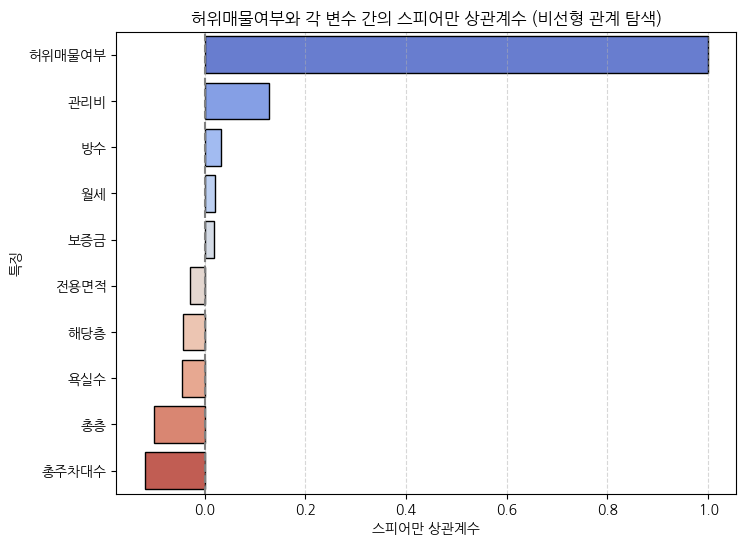

In [9]:
# 숫자형 컬럼만 선택
numeric_cols = train_data.select_dtypes(include=["number"])

# 스피어만 상관계수 계산
spearman_corr = numeric_cols.corr(method="spearman")["허위매물여부"].sort_values(ascending=False)

# 시각화
plt.figure(figsize=(8, 6))
sns.barplot(x=spearman_corr.values, y=spearman_corr.index, palette="coolwarm", edgecolor="black")

plt.xlabel("스피어만 상관계수")
plt.ylabel("특징")
plt.title("허위매물여부와 각 변수 간의 스피어만 상관계수 (비선형 관계 탐색)")
plt.axvline(x=0, color="gray", linestyle="--")  # 0 기준선 추가
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.show()


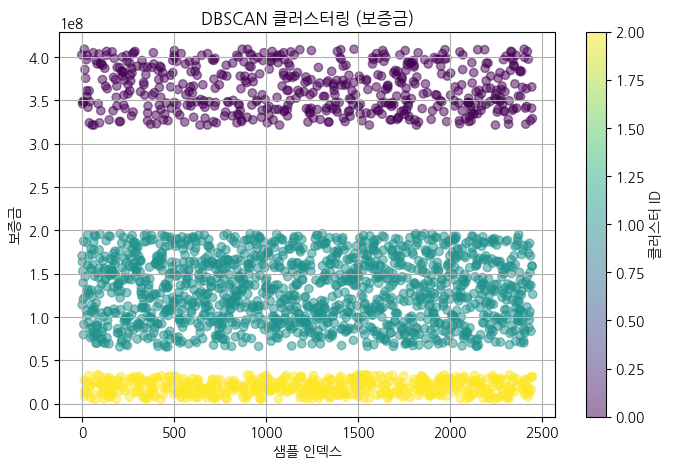

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import MinMaxScaler

# 데이터 불러오기 (train_data가 있다고 가정)
deposit_column = "보증금"

# 결측치 제거 및 스케일링
train_data = train_data.dropna(subset=[deposit_column])  # 결측치 제거
scaler = MinMaxScaler()
deposit_scaled = scaler.fit_transform(train_data[[deposit_column]])

# DBSCAN 클러스터링 적용
dbscan = DBSCAN(eps=0.05, min_samples=5)  # eps와 min_samples 조정 가능
clusters = dbscan.fit_predict(deposit_scaled)

# 클러스터 결과를 데이터프레임에 추가
train_data["보증금_cluster"] = clusters

# 클러스터링 결과 시각화
plt.figure(figsize=(8, 5))
plt.scatter(train_data.index, train_data[deposit_column], c=clusters, cmap='viridis', alpha=0.5)
plt.xlabel("샘플 인덱스")
plt.ylabel("보증금")
plt.title("DBSCAN 클러스터링 (보증금)")
plt.colorbar(label="클러스터 ID")
plt.grid(True)
plt.show()


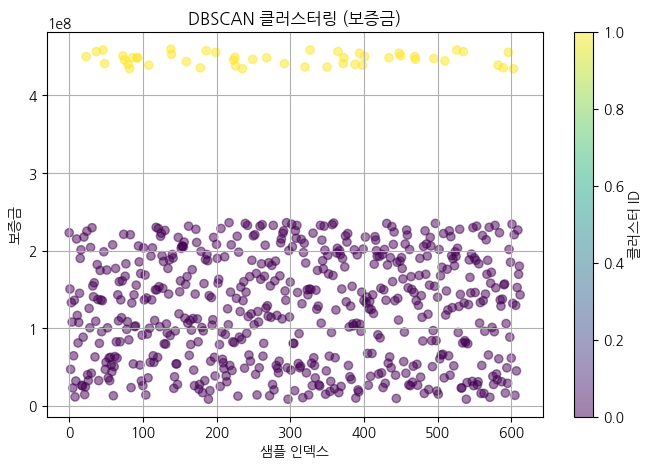

In [11]:
# 데이터 불러오기 (train_data가 있다고 가정)
deposit_column = "보증금"

# 결측치 제거 및 스케일링
# test_data = test_data.dropna(subset=[deposit_column])  # 결측치 제거
# scaler = StandardScaler()
deposit_scaled = scaler.fit_transform(test_data[[deposit_column]])

# DBSCAN 클러스터링 적용
# dbscan = DBSCAN(eps=0.1, min_samples=5)  # eps와 min_samples 조정 가능
clusters = dbscan.fit_predict(deposit_scaled)

# 클러스터 결과를 데이터프레임에 추가
test_data["보증금_cluster"] = clusters

# 클러스터링 결과 시각화
plt.figure(figsize=(8, 5))
plt.scatter(test_data.index, test_data[deposit_column], c=clusters, cmap='viridis', alpha=0.5)
plt.xlabel("샘플 인덱스")
plt.ylabel("보증금")
plt.title("DBSCAN 클러스터링 (보증금)")
plt.colorbar(label="클러스터 ID")
plt.grid(True)
plt.show()

In [12]:
# 날짜 컬럼 라벨 인코딩
# === 레이블 인코딩 ===
label_encode_cols = ['중개사무소', '게재일']
for col in label_encode_cols:
    le = LabelEncoder()
    combined_data = pd.concat([train_data[col], test_data[col]], axis=0).astype(str)
    le.fit(combined_data)
    train_data[col] = le.transform(train_data[col].astype(str))
    test_data[col] = le.transform(test_data[col].astype(str))

# 범주형 변수 원-핫 인코딩
categorical_cols = train_data.select_dtypes(include=['object']).columns.tolist()
categorical_cols.remove("ID")
train_data = pd.get_dummies(train_data, columns=categorical_cols, drop_first=True, dtype=int)
test_data = pd.get_dummies(test_data, columns=categorical_cols, drop_first=True, dtype=int)

In [13]:
# train_data["중개사무소_전화확인비율"] = train_data.groupby("중개사무소")["매물확인방식_전화확인"].transform("mean")
# test_data["중개사무소_전화확인비율"] = test_data.groupby("중개사무소")["매물확인방식_전화확인"].transform("mean")

# train_data["중개사무소_현장확인비율"] = train_data.groupby("중개사무소")["매물확인방식_현장확인"].transform("mean")
# test_data["중개사무소_현장확인비율"] = test_data.groupby("중개사무소")["매물확인방식_현장확인"].transform("mean")


# 중개사무소의 허위매물 비율
# train_data["중개사무소_허위매물비율"] = train_data.groupby("중개사무소")["허위매물여부"].transform("mean")

# 중개사무소별 일일 매물 등록 건수 계산
# train_data["중개사무소_일일등록건수"] = train_data.groupby(["중개사무소", "게재일"])["ID"].transform("count")
# test_data["중개사무소_일일등록건수"] = test_data.groupby(["중개사무소", "게재일"])["ID"].transform("count")

# 중개사무소의 최근 30일 등록 빈도 (훈련 데이터 기준 최대 게재일 활용)
# max_train_date = train_data["게재일"].max()
# train_data["중개사무소_최근등록빈도"] = train_data.groupby("중개사무소")["게재일"].transform(lambda x: (x >= max_train_date - 30).sum())
# test_data["중개사무소_최근등록빈도"] = test_data.groupby("중개사무소")["게재일"].transform(lambda x: (x >= max_train_date - 30).sum())



In [14]:
train_data

,ID,보증금,월세,전용면적,해당층,총층,방수,욕실수,총주차대수,관리비,...,제공플랫폼_D플랫폼,제공플랫폼_E플랫폼,제공플랫폼_F플랫폼,제공플랫폼_G플랫폼,제공플랫폼_H플랫폼,제공플랫폼_I플랫폼,제공플랫폼_J플랫폼,제공플랫폼_K플랫폼,제공플랫폼_L플랫폼,제공플랫폼_M플랫폼
0,TRAIN_0000,402500000.0,470000.0,27.180,3.2,15.0,1.0,1.0,40.0,96.0,...,0,0,0,0,0,0,0,0,0,0
1,TRAIN_0001,170500000.0,200000.0,20.102,3.0,4.0,2.0,1.0,14.2,0.0,...,1,0,0,0,0,0,0,0,0,0
2,TRAIN_0002,114000000.0,380000.0,29.574,2.0,3.0,1.0,1.0,13.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,TRAIN_0003,163500000.0,30000.0,36.300,3.0,9.0,2.0,1.0,13.0,10.0,...,0,0,0,0,0,0,0,0,0,0
4,TRAIN_0004,346000000.0,530000.0,25.760,3.0,3.0,2.0,1.0,11.8,0.0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2447,TRAIN_2447,159000000.0,550000.0,48.950,3.0,3.0,2.0,1.0,34.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2448,TRAIN_2448,158500000.0,750000.0,31.516,2.0,4.0,1.0,1.0,18.6,2.0,...,0,0,0,0,0,0,0,0,0,0
2449,TRAIN_2449,329000000.0,610000.0,17.500,8.0,20.0,1.0,1.0,29.0,10.0,...,0,0,0,0,0,0,0,0,0,0
2450,TRAIN_2450,31000000.0,400000.0,22.870,8.0,9.0,2.0,1.0,26.6,8.0,...,0,0,0,0,0,0,0,0,0,0


C:\Users\HOST\AppData\Local\Temp\ipykernel_40452\2054322390.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=spearman_corr.values, y=spearman_corr.index, palette="coolwarm", edgecolor="black")


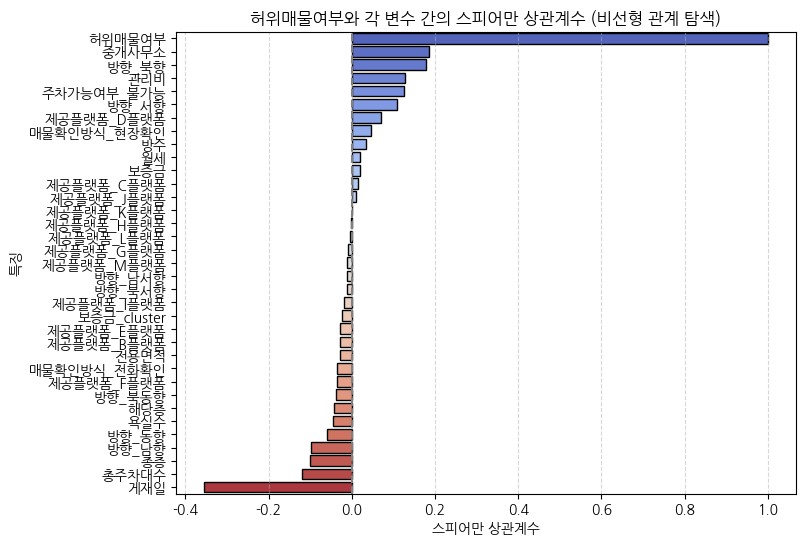

In [15]:
# 숫자형 컬럼만 선택
numeric_cols = train_data.select_dtypes(include=["number"])

# 스피어만 상관계수 계산
spearman_corr = numeric_cols.corr(method="spearman")["허위매물여부"].sort_values(ascending=False)

# 시각화
plt.figure(figsize=(8, 6))
sns.barplot(x=spearman_corr.values, y=spearman_corr.index, palette="coolwarm", edgecolor="black")

plt.xlabel("스피어만 상관계수")
plt.ylabel("특징")
plt.title("허위매물여부와 각 변수 간의 스피어만 상관계수 (비선형 관계 탐색)")
plt.axvline(x=0, color="gray", linestyle="--")  # 0 기준선 추가
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.show()


In [16]:
set(test_data.columns) - (set(train_data.columns) | {"허위매물여부"})

{'제공플랫폼_N플랫폼'}

In [17]:
# train_data와 test_data의 컬럼 차이를 확인
train_cols = set(train_data.columns)
test_cols = set(test_data.columns)

# train에만 있는 컬럼과 test에만 있는 컬럼 찾기
unique_train_cols = train_cols - (test_cols | {"허위매물여부"})  # train에만 존재하는 컬럼
unique_test_cols = test_cols - train_cols  # test에만 존재하는 컬럼

# 삭제할 컬럼 목록 (train, test 중 한쪽에만 존재하는 컬럼들)
cols_to_remove = unique_train_cols | unique_test_cols

# train_data와 test_data에서 해당 컬럼 제거
train_data = train_data.drop(columns=cols_to_remove, errors='ignore')
test_data = test_data.drop(columns=cols_to_remove, errors='ignore')

# 컬럼 순서 정렬 (동일한 컬럼 유지)
train_data = train_data[sorted(train_data.columns)]
test_data = test_data[sorted(test_data.columns)]

# 삭제된 컬럼 출력
print(f"삭제된 컬럼: {cols_to_remove}")

# 확인
train_data.shape, test_data.shape


삭제된 컬럼: {'제공플랫폼_M플랫폼', '제공플랫폼_N플랫폼', '제공플랫폼_J플랫폼'}


((2452, 34), (613, 33))

In [18]:
train_data.to_csv("preprocess_train.csv", index=False)
test_data.to_csv("preprocess_test.csv", index=False)

In [19]:
train_data.columns.tolist

<bound method IndexOpsMixin.tolist of Index(['ID', '게재일', '관리비', '매물확인방식_전화확인', '매물확인방식_현장확인', '방수', '방향_남서향',
       '방향_남향', '방향_동향', '방향_북동향', '방향_북서향', '방향_북향', '방향_서향', '보증금',
       '보증금_cluster', '욕실수', '월세', '전용면적', '제공플랫폼_B플랫폼', '제공플랫폼_C플랫폼',
       '제공플랫폼_D플랫폼', '제공플랫폼_E플랫폼', '제공플랫폼_F플랫폼', '제공플랫폼_G플랫폼', '제공플랫폼_H플랫폼',
       '제공플랫폼_I플랫폼', '제공플랫폼_K플랫폼', '제공플랫폼_L플랫폼', '주차가능여부_불가능', '중개사무소',
       '총주차대수', '총층', '해당층', '허위매물여부'],
      dtype='object')>